In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
DATA_PATH = Path(
    r"D:\UPI_Fraud_Detection_Project_ML\data\upi_fraud_detection_dataset_100k.csv"
)

In [6]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

sns.set_theme(style="whitegrid")

print("Dataset Loaded Successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Fraud rate:", round(df["is_fraud"].mean() * 100, 2), "%")

df.head()

Dataset Loaded Successfully!
Rows: 100000
Columns: 22
Fraud rate: 1.59 %


,transaction_id,user_id,timestamp,amount,merchant_category,transaction_type,sender_bank,receiver_bank,device_type,os,...,device_trust_score,failed_attempts,transaction_velocity,account_age_days,is_new_device,is_new_location,beneficiary_age_days,hour,is_weekend,is_fraud
0,TXN00000001,USR001339,2026-07-20 17:27:54,154.25,Food,Bill Payment,Kotak,SBI,Android,Android 15,...,91.88,0,4,2472,0,0,932,17,0,0
1,TXN00000002,USR011610,2026-08-29 20:08:54,102.42,Utilities,Bill Payment,Axis,Kotak,Android,Android 14,...,96.16,0,2,163,0,0,1166,20,1,0
2,TXN00000003,USR009819,2026-06-06 02:13:15,324.43,Travel,Merchant Payment,IDFC First,Kotak,Android,Android 15,...,77.42,1,2,368,0,0,392,2,1,0
3,TXN00000004,USR006584,2026-04-24 00:45:32,42.56,Shopping,Merchant Payment,IndusInd,IDFC First,Android,Android 14,...,96.22,1,3,953,0,1,490,0,0,0
4,TXN00000005,USR006496,2026-01-02 06:16:25,42.32,Education,Bank Transfer,IndusInd,ICICI,Android,Android 15,...,69.86,0,2,104,0,0,665,6,0,0


### Fraud vs Legitimate transactions

In [7]:
fraud_counts = df["is_fraud"].value_counts().sort_index()

print("Legitimate transactions:", fraud_counts.get(0, 0))
print("Fraud transactions:", fraud_counts.get(1, 0))

Legitimate transactions: 98412
Fraud transactions: 1588


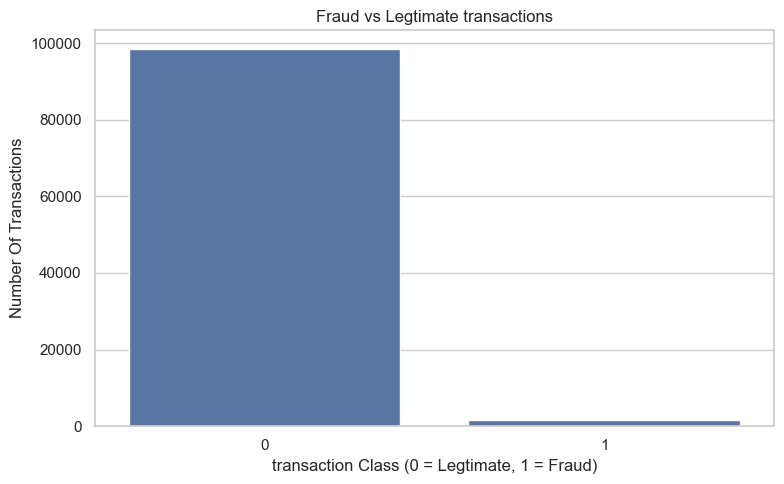

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="is_fraud")
plt.title("Fraud vs Legtimate transactions")
plt.xlabel("transaction Class (0 = Legtimate, 1 = Fraud)")
plt.ylabel("Number Of Transactions")

plt.tight_layout()
plt.show()

### Transaction amount analysis

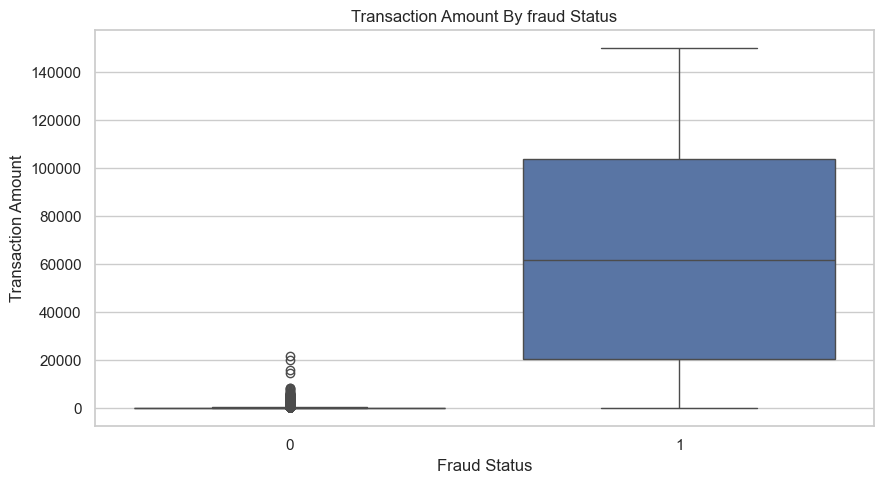

In [9]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="is_fraud", y="amount")

plt.title("Transaction Amount By fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

### Risk features analysis

In [ ]:
risk_features = [
    "ip_risk_score",
    "device_trust_score",
    "failed_attempts",
    "transaction_velocity",
    "account_age_days",
    "beneficiary_age_days",
]

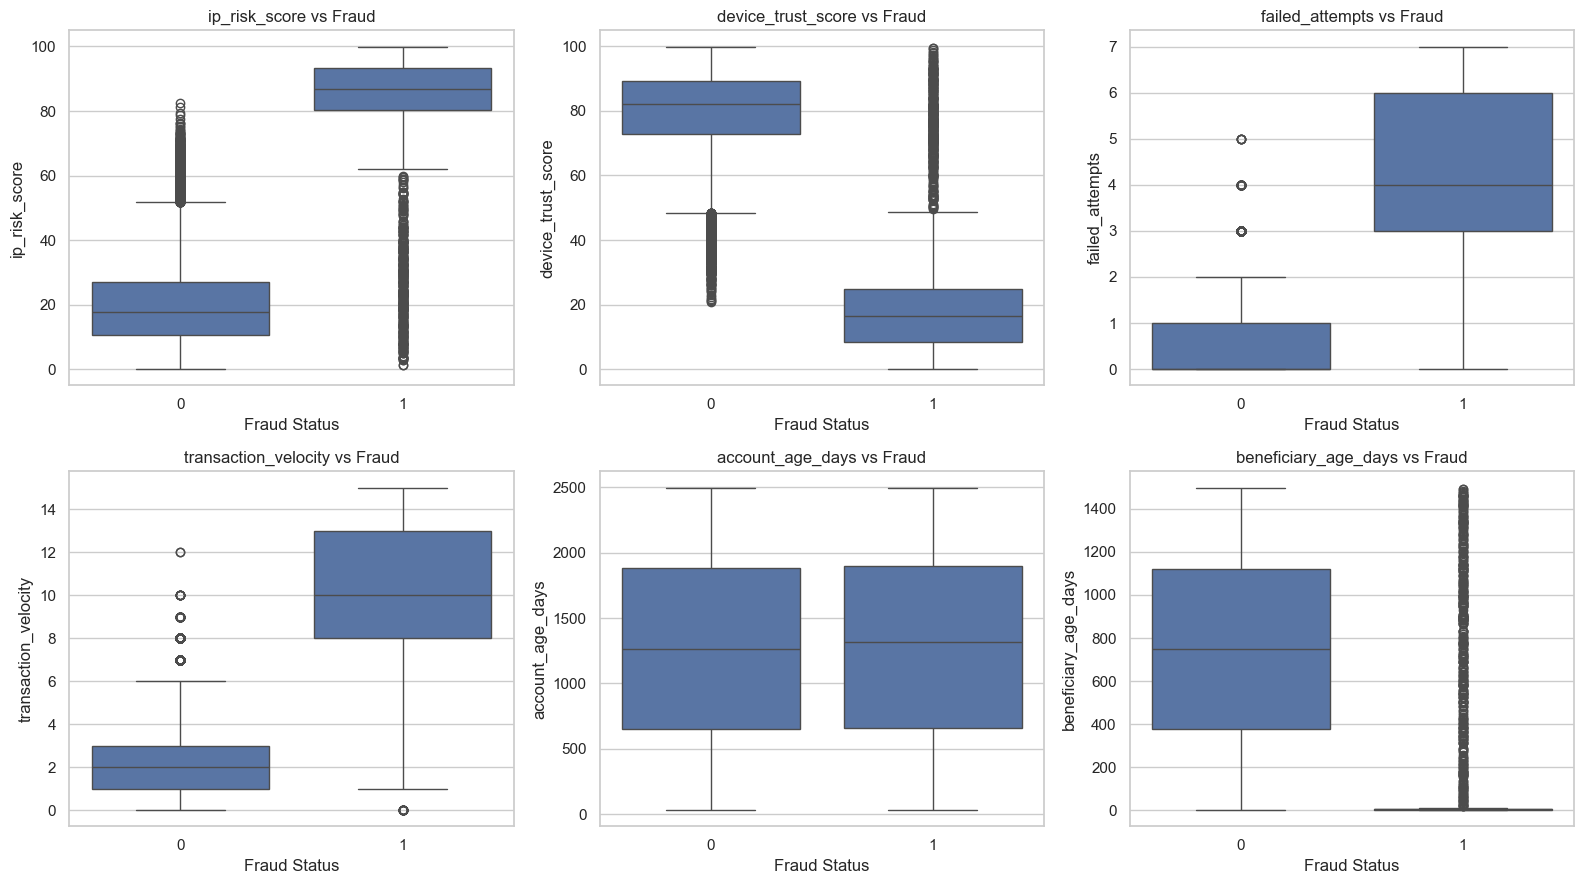

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), risk_features):
    sns.boxplot(data=df, x="is_fraud", y=feature, ax=ax)
    ax.set_title(f"{feature} vs Fraud")
    ax.set_xlabel("Fraud Status")

plt.tight_layout()
plt.show()

### Fraud by transaction type

In [ ]:
fraud_by_type = (
    df.groupby("transaction_type")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "total_transactions",
            "sum": "fraud_transactions",
            "mean": "fraud_rate",
        }
    )
)

fraud_by_type["fraud_rate_pct"] = (fraud_by_type["fraud_rate"] * 100).round(2)

display(fraud_by_type.sort_values("fraud_rate_pct", ascending=False))

,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
transaction_type,,,,
Recharge,13017,228,0.017516,1.75
Merchant Payment,30156,496,0.016448,1.64
P2P,35029,547,0.015616,1.56
Bill Payment,11902,179,0.015039,1.50
Bank Transfer,9896,138,0.013945,1.39


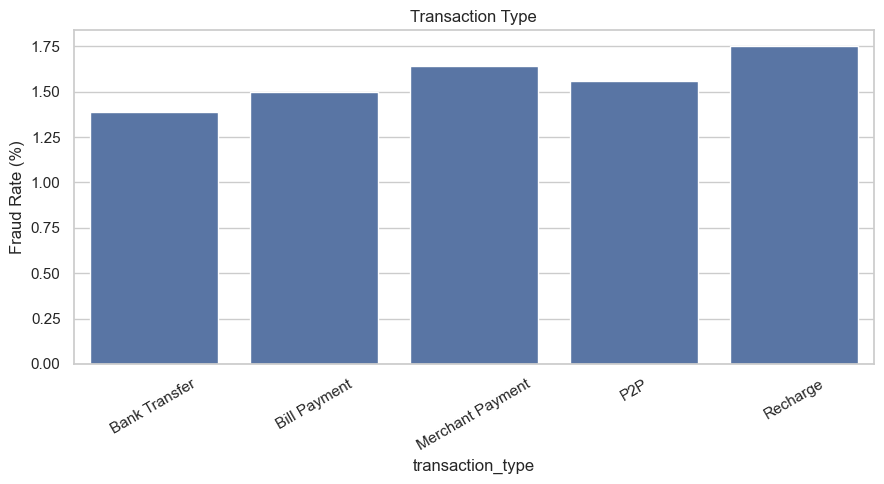

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(data=fraud_by_type.reset_index(), x="transaction_type", y="fraud_rate_pct")

plt.title("Fraud Rate by Transaction Type")
plt.title("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Fraud by merchant category

In [ ]:
merchant_analysis = df.groupby("merchant_category")["is_fraud"].agg(
    total_transactions="count", fraud_transactions="sum", fraud_rate="mean"
)
merchant_analysis["fraud_rate_pct"] = (merchant_analysis["fraud_rate"] * 100).round(2)

display(merchant_analysis.sort_values("fraud_rate_pct", ascending=False))

,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
merchant_category,,,,
Healthcare,8266,160,0.019356,1.94
Bills,8172,156,0.019090,1.91
Groceries,8446,145,0.017168,1.72
Education,8422,138,0.016386,1.64
Utilities,8462,135,0.015954,1.60
Shopping,8274,125,0.015108,1.51
Travel,8325,125,0.015015,1.50
Electronics,8449,123,0.014558,1.46
Food,8308,121,0.014564,1.46


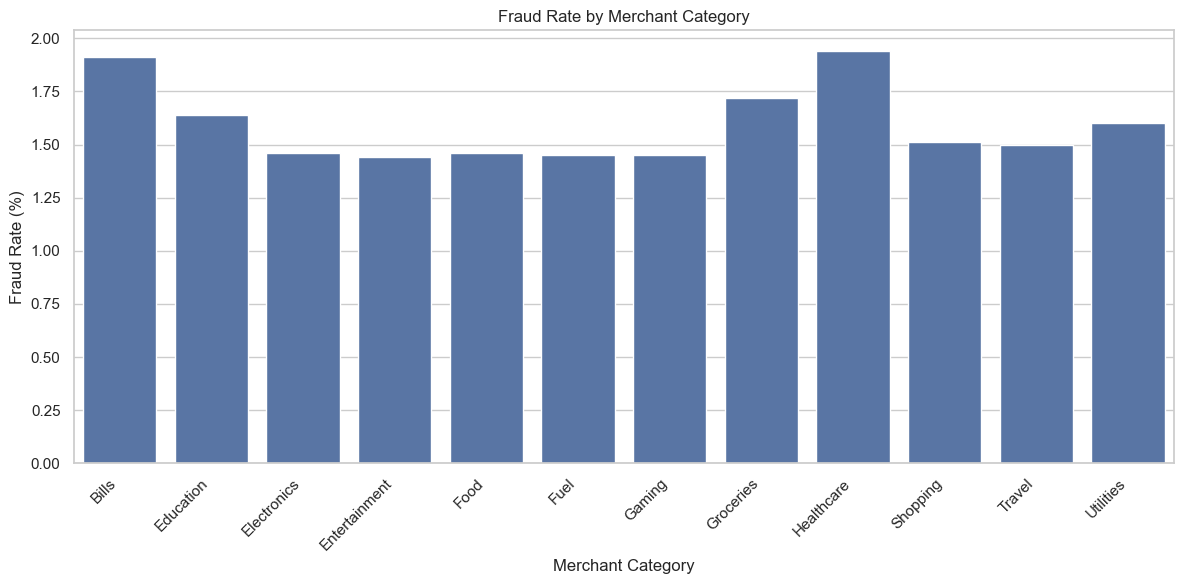

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=merchant_analysis.reset_index(), x="merchant_category", y="fraud_rate_pct"
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Fraud by hour

In [ ]:
hour_analysis = df.groupby("hour")["is_fraud"].agg(
    total_transaction="count", fraud_transactions="sum", fraud_rate="mean"
)

hour_analysis["fraud_rate_pct"] = (hour_analysis["fraud_rate"] * 100).round(2)

display(hour_analysis)

,total_transaction,fraud_transactions,fraud_rate,fraud_rate_pct
hour,,,,
0,4234,85,0.020076,2.01
1,4209,92,0.021858,2.19
2,4092,88,0.021505,2.15
3,4155,87,0.020939,2.09
4,4119,76,0.018451,1.85
5,4159,51,0.012263,1.23
6,4207,68,0.016164,1.62
7,4152,55,0.013247,1.32
8,4260,63,0.014789,1.48


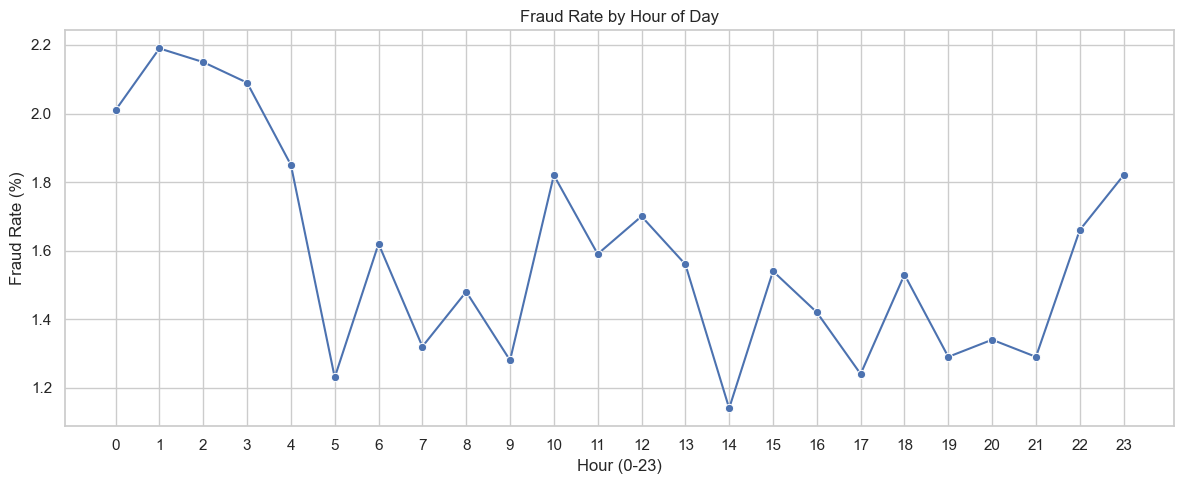

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=hour_analysis.reset_index(), x="hour", y="fraud_rate_pct", marker="o")

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour (0-23)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

### New device And new location analysis

In [ ]:
for feature in ["is_new_device", "is_new_location", "is_weekend"]:
    analysis = df.groupby(feature)["is_fraud"].agg(
        total_transactions="count", fraud_transactions="sum", fraud_rate="mean"
    )

    analysis["fraud_rate_pct"] = (analysis["fraud_rate"] * 100).round(2)

    print(f"\nAnalysis:{feature}")
    display(analysis)


Analysis:is_new_device


,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
is_new_device,,,,
0,90859,285,0.003137,0.31
1,9141,1303,0.142545,14.25



Analysis:is_new_location


,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
is_new_location,,,,
0,88855,302,0.003399,0.34
1,11145,1286,0.115388,11.54



Analysis:is_weekend


,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
is_weekend,,,,
0,71581,1172,0.016373,1.64
1,28419,416,0.014638,1.46


### Correlation heatmap

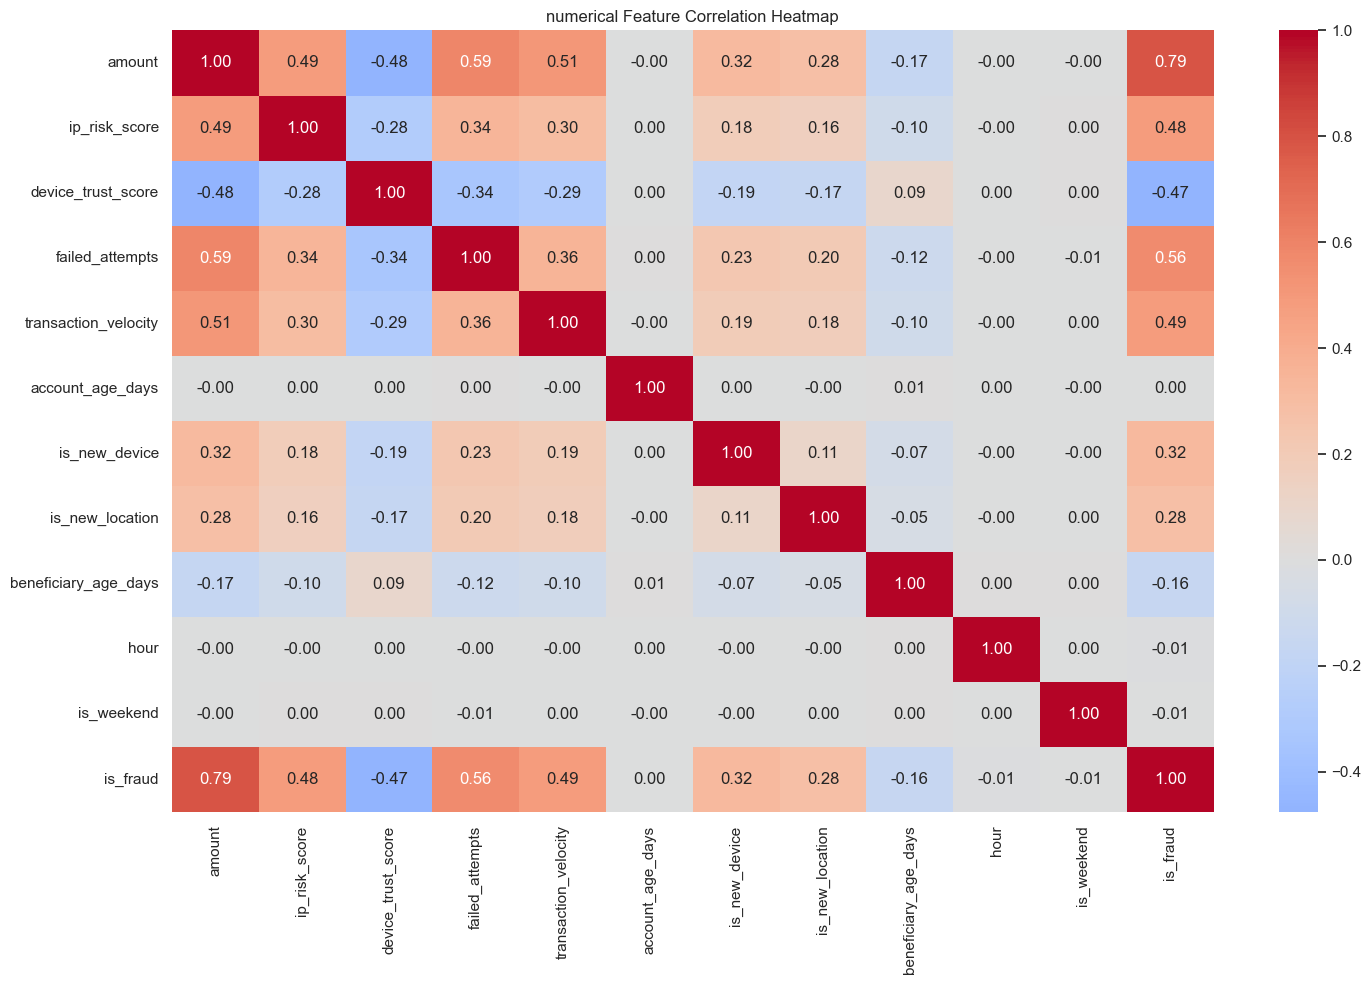

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(15, 10))

sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()